# 🔬 RAG Evaluation Dataset Generation Experiment

This notebook implements a research-grade pipeline to:
1. Generate QA pairs from PDF documents using Gemini
2. Filter pairs using LLM-as-Judge critique
3. Build a RAG pipeline with ChromaDB
4. Evaluate retrieval and generation quality

**Target: 200+ high-quality QA pairs for statistical significance**

---
## 1. Environment Setup

In [1]:
# Install required packages
!pip install -q google-genai kagglehub chromadb json-repair pandas tqdm openpyxl python-dotenv langchain langchain-text-splitters PyPDF2 rouge-score nltk scikit-learn

In [2]:
import os
import json
import time
import warnings
from pathlib import Path
from typing import List, Dict, Optional

import pandas as pd
import numpy as np
from tqdm.auto import tqdm
import json_repair

# Google GenAI
from google import genai
from google.genai import types

# ChromaDB
import chromadb
from chromadb.utils import embedding_functions

# PDF Processing
from PyPDF2 import PdfReader
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Evaluation
from rouge_score import rouge_scorer
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from sklearn.metrics.pairwise import cosine_similarity

# Download NLTK data
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

warnings.filterwarnings('ignore')

print("✅ All packages imported successfully!")

✅ All packages imported successfully!


In [8]:
# ============================================================
# 🔑 API KEY CONFIGURATION
# ============================================================
# Option 1: Set directly (not recommended for production)
# os.environ['GOOGLE_API_KEY'] = 'your-api-key-here'

# Option 2: Load from .env file (recommended)
from dotenv import load_dotenv
load_dotenv()

# Verify API key is set
GOOGLE_API_KEY = os.environ.get('GOOGLE_API_KEY')

if not GOOGLE_API_KEY:
    GOOGLE_API_KEY = input("Enter your Google API Key: ")
    os.environ['GOOGLE_API_KEY'] = GOOGLE_API_KEY

# Initialize Gemini client
client = genai.Client(api_key=GOOGLE_API_KEY)

# Configuration
MODEL_NAME = "gemini-2.0-flash"  # Fast and free tier friendly
EMBEDDING_MODEL = "text-embedding-004"  # Latest Google embedding model
REQUEST_DELAY = 4  # Seconds between API calls to stay under 15 RPM

print(f"✅ Gemini client initialized with model: {MODEL_NAME}")

✅ Gemini client initialized with model: gemini-2.0-flash


---
## 2. Dataset Download

In [4]:
import kagglehub

# Download dataset from Kaggle
# Note: Make sure you have Kaggle credentials configured
# You can set them via: kaggle.json file or environment variables
# KAGGLE_USERNAME and KAGGLE_KEY

print("📥 Downloading PDF dataset from Kaggle...")
dataset_path = kagglehub.dataset_download("manisha717/dataset-of-pdf-files")
print(f"✅ Dataset downloaded to: {dataset_path}")

📥 Downloading PDF dataset from Kaggle...


100%|██████████| 769M/769M [00:09<00:00, 88.0MB/s]

Extracting files...


✅ Dataset downloaded to: /root/.cache/kagglehub/datasets/manisha717/dataset-of-pdf-files/versions/1


In [11]:
# Get all PDF files
pdf_files = list(Path(dataset_path).rglob("*.pdf"))
print(f"📚 Found {len(pdf_files)} PDF files")

# Sample files for experiment (70 files → ~210 QA pairs → ~150-200 after filtering)
NUM_FILES_TO_PROCESS = 5
QA_PAIRS_PER_FILE = 3

# Randomly sample files for diversity
np.random.seed(42)  # For reproducibility
sampled_files = np.random.choice(pdf_files, size=min(NUM_FILES_TO_PROCESS, len(pdf_files)), replace=False)
print(f"🎯 Selected {len(sampled_files)} files for processing")

# Display sample
print("\n📄 Sample files:")
for f in sampled_files[:5]:
    print(f"  - {f.name}")

📚 Found 1076 PDF files
🎯 Selected 5 files for processing

📄 Sample files:
  - ST6INBKMLTFTUDWNHVI433RTQ5KYCWHG.pdf
  - 74JU6CDDK5QMBF2HTCNUWTUTJZJONVWI.pdf
  - 6C4F5OS4HOEBDQEKSVUX42XOMOJG3BNW.pdf
  - IPSOTZ2PBHPSDMON7CRCOAQD5CNYYOVE.pdf
  - WXR2YY3TSXGUNVC2VECKTVIJO7PMECRS.pdf


---
## 3. QA Pair Generation

In [6]:
# Specialized QA Generation Prompt
QA_GENERATION_PROMPT = """
You are an expert at creating high-quality question-answer pairs for evaluating RAG (Retrieval-Augmented Generation) systems.

Given this PDF document, generate exactly {num_pairs} question-answer pairs that:

1. **Are fact-based**: Questions should have clear, factual answers derivable from the document
2. **Are search-engine style**: Questions should be phrased as a user would type into a search engine
3. **Require synthesis**: Answers should ideally require combining information from multiple parts of the document
4. **Are standalone**: Questions should be understandable without seeing the document
5. **Are diverse**: Cover different topics/sections of the document

For each QA pair, also provide:
- The page number(s) where the answer can be found
- A brief context snippet (1-2 sentences) from the document supporting the answer

Return your response as a valid JSON array with this exact structure:
[
  {{
    "question": "The question text",
    "answer": "The comprehensive answer",
    "pages": [1, 2],
    "context": "Supporting context from the document"
  }}
]

IMPORTANT: Return ONLY the JSON array, no additional text or markdown formatting.
"""

def upload_pdf_to_gemini(file_path: Path) -> Optional[types.File]:
    """Upload a PDF file to Gemini for processing."""
    try:
        uploaded_file = client.files.upload(file=file_path)
        return uploaded_file
    except Exception as e:
        print(f"❌ Error uploading {file_path.name}: {e}")
        return None

def generate_qa_pairs(file_path: Path, num_pairs: int = 3) -> List[Dict]:
    """Generate QA pairs for a PDF file using Gemini."""
    try:
        # Upload PDF to Gemini
        uploaded_file = upload_pdf_to_gemini(file_path)
        if not uploaded_file:
            return []

        # Generate QA pairs
        prompt = QA_GENERATION_PROMPT.format(num_pairs=num_pairs)

        response = client.models.generate_content(
            model=MODEL_NAME,
            contents=[
                types.Content(
                    role="user",
                    parts=[
                        types.Part.from_uri(
                            file_uri=uploaded_file.uri,
                            mime_type="application/pdf"
                        ),
                        types.Part.from_text(text=prompt)
                    ]
                )
            ],
            config=types.GenerateContentConfig(
                temperature=0.3,
                max_output_tokens=2048
            )
        )

        # Parse response
        response_text = response.text.strip()

        # Try to repair JSON if needed
        qa_pairs = json_repair.loads(response_text)

        # Add source file info
        for pair in qa_pairs:
            pair['source_file'] = file_path.name
            pair['source_path'] = str(file_path)

        # Cleanup uploaded file
        try:
            client.files.delete(name=uploaded_file.name)
        except:
            pass

        return qa_pairs

    except Exception as e:
        print(f"❌ Error generating QA for {file_path.name}: {e}")
        return []

print("✅ QA generation functions defined")

✅ QA generation functions defined


In [12]:
# Generate QA pairs for all sampled files
all_qa_pairs = []
failed_files = []

print(f"🚀 Generating QA pairs for {len(sampled_files)} files...")
print(f"⏱️  Estimated time: ~{len(sampled_files) * REQUEST_DELAY // 60} minutes\n")

for i, file_path in enumerate(tqdm(sampled_files, desc="Processing PDFs")):
    try:
        qa_pairs = generate_qa_pairs(file_path, num_pairs=QA_PAIRS_PER_FILE)

        if qa_pairs:
            all_qa_pairs.extend(qa_pairs)
            tqdm.write(f"✅ {file_path.name}: Generated {len(qa_pairs)} pairs")
        else:
            failed_files.append(file_path.name)
            tqdm.write(f"⚠️ {file_path.name}: No pairs generated")

        # Rate limiting
        if i < len(sampled_files) - 1:
            time.sleep(REQUEST_DELAY)

    except Exception as e:
        failed_files.append(file_path.name)
        tqdm.write(f"❌ {file_path.name}: Error - {str(e)[:50]}")
        time.sleep(REQUEST_DELAY)

print(f"\n📊 Generation Summary:")
print(f"   Total QA pairs generated: {len(all_qa_pairs)}")
print(f"   Files processed successfully: {len(sampled_files) - len(failed_files)}")
print(f"   Failed files: {len(failed_files)}")

🚀 Generating QA pairs for 5 files...
⏱️  Estimated time: ~0 minutes



Processing PDFs:   0%|          | 0/5 [00:00<?, ?it/s]

✅ ST6INBKMLTFTUDWNHVI433RTQ5KYCWHG.pdf: Generated 3 pairs
✅ 74JU6CDDK5QMBF2HTCNUWTUTJZJONVWI.pdf: Generated 3 pairs
✅ 6C4F5OS4HOEBDQEKSVUX42XOMOJG3BNW.pdf: Generated 3 pairs
✅ IPSOTZ2PBHPSDMON7CRCOAQD5CNYYOVE.pdf: Generated 3 pairs
✅ WXR2YY3TSXGUNVC2VECKTVIJO7PMECRS.pdf: Generated 3 pairs

📊 Generation Summary:
   Total QA pairs generated: 15
   Files processed successfully: 5
   Failed files: 0


In [13]:
# Convert to DataFrame for easier manipulation
raw_qa_df = pd.DataFrame(all_qa_pairs)
print(f"📋 Raw QA DataFrame shape: {raw_qa_df.shape}")
raw_qa_df.head()

📋 Raw QA DataFrame shape: (15, 6)


,question,answer,pages,context,source_file,source_path
0,What did Rep. Steve Israel request regarding W...,Rep. Steve Israel requested the National Archi...,[1],In the FY2009 Financial Services Appropriation...,ST6INBKMLTFTUDWNHVI433RTQ5KYCWHG.pdf,/root/.cache/kagglehub/datasets/manisha717/dat...
1,What topics are covered in the declassified WW...,The report covers topics such as the first que...,[1],The report covers the following topics: New re...,ST6INBKMLTFTUDWNHVI433RTQ5KYCWHG.pdf,/root/.cache/kagglehub/datasets/manisha717/dat...
2,"What was ""Project Happiness"" related to in the...","""Project Happiness"" was the CIC's codename for...",[1],"Discussion of approximately 1,200 newly releas...",ST6INBKMLTFTUDWNHVI433RTQ5KYCWHG.pdf,/root/.cache/kagglehub/datasets/manisha717/dat...
3,What is included and not included in the defin...,"According to Initiative 710, the definition of...",[1],"For the purposes of this section, ""tax"" includ...",74JU6CDDK5QMBF2HTCNUWTUTJZJONVWI.pdf,/root/.cache/kagglehub/datasets/manisha717/dat...
4,What does Initiative 710 say about property ta...,Initiative 710 states that the valuation of pr...,[2],The valuation of property can only be increase...,74JU6CDDK5QMBF2HTCNUWTUTJZJONVWI.pdf,/root/.cache/kagglehub/datasets/manisha717/dat...


---
## 4. LLM-as-Judge Critique & Filtering

In [14]:
# LLM-as-Judge Critique Prompt
CRITIQUE_PROMPT = """
You are an expert evaluator for RAG (Retrieval-Augmented Generation) question-answer pairs.

Evaluate the following QA pair on these four criteria, scoring each from 1-5:

1. **Groundedness** (1-5): Is the answer fully supported by the provided context?
   - 5: Completely supported, all facts are in the context
   - 1: Answer contains information not in the context

2. **Relevance** (1-5): Is the question relevant to the document's main topics?
   - 5: Highly relevant, about core content
   - 1: Irrelevant or about trivial details

3. **Standalone** (1-5): Can the question be understood without seeing the document?
   - 5: Completely self-contained
   - 1: Requires document context to understand

4. **Quality** (1-5): Overall quality for RAG evaluation purposes
   - 5: Excellent for testing RAG systems
   - 1: Poor quality, not useful for evaluation

QA Pair to evaluate:
- Question: {question}
- Answer: {answer}
- Context: {context}
- Source: {source_file}

Return your evaluation as a valid JSON object:
{{
  "groundedness": <score>,
  "relevance": <score>,
  "standalone": <score>,
  "quality": <score>,
  "reasoning": "Brief explanation of scores"
}}

IMPORTANT: Return ONLY the JSON object, no additional text.
"""

def critique_qa_pair(qa_pair: Dict) -> Dict:
    """Critique a single QA pair using LLM-as-Judge."""
    try:
        prompt = CRITIQUE_PROMPT.format(
            question=qa_pair.get('question', ''),
            answer=qa_pair.get('answer', ''),
            context=qa_pair.get('context', ''),
            source_file=qa_pair.get('source_file', '')
        )

        response = client.models.generate_content(
            model=MODEL_NAME,
            contents=prompt,
            config=types.GenerateContentConfig(
                temperature=0.1,
                max_output_tokens=512
            )
        )

        # Parse response
        critique = json_repair.loads(response.text.strip())
        return critique

    except Exception as e:
        print(f"❌ Critique error: {e}")
        return {
            "groundedness": 0,
            "relevance": 0,
            "standalone": 0,
            "quality": 0,
            "reasoning": f"Error: {str(e)}"
        }

print("✅ Critique functions defined")

✅ Critique functions defined


## How to run this notebook locally

To run this notebook on your local machine, follow these steps:

### 1. Environment Setup

Ensure you have Python (3.9+) installed. Create a virtual environment (recommended):

```bash
python -m venv venv
source venv/bin/activate  # On Windows, use `venv\Scripts\activate`
```

### 2. Install Dependencies

Install all the required packages using pip:

```bash
pip install -q google-genai kagglehub chromadb json-repair pandas tqdm openpyxl python-dotenv langchain langchain-text-splitters PyPDF2 rouge-score nltk scikit-learn
```

### 3. Configure Google API Key

Create a `.env` file in the same directory as your notebook and add your Google API Key:

```dotenv
GOOGLE_API_KEY='your-api-key-here'
```

Make sure to replace `'your-api-key-here'` with your actual Gemini API key. The notebook uses `python-dotenv` to load this key.

### 4. Configure Kaggle Credentials

To download the dataset from Kaggle, you need to set up your Kaggle API credentials. Follow these steps:

1.  Go to your Kaggle account page (Profile -> Account).
2.  Scroll down to the 'API' section and click 'Create New API Token'. This will download `kaggle.json`.
3.  Place `kaggle.json` in the directory `~/.kaggle/` (for Linux/macOS) or `C:\Users\<Windows-username>\.kaggle\` (for Windows). Ensure the file permissions are correct (e.g., `chmod 600 ~/.kaggle/kaggle.json`).

Alternatively, you can set `KAGGLE_USERNAME` and `KAGGLE_KEY` as environment variables.

### 5. Run the Notebook

Once the environment is set up and dependencies are installed, you can open the `.ipynb` file with Jupyter Notebook or JupyterLab and run the cells sequentially. The `kagglehub.dataset_download` function will automatically download the PDF dataset to a local cache directory.

In [15]:
# Run critique on all QA pairs
print(f"🔍 Running LLM-as-Judge critique on {len(all_qa_pairs)} QA pairs...")
print(f"⏱️  Estimated time: ~{len(all_qa_pairs) * REQUEST_DELAY // 60} minutes\n")

critiqued_pairs = []

for i, pair in enumerate(tqdm(all_qa_pairs, desc="Critiquing QA pairs")):
    critique = critique_qa_pair(pair)

    # Merge critique scores with original pair
    enriched_pair = {**pair, **critique}
    critiqued_pairs.append(enriched_pair)

    # Rate limiting
    if i < len(all_qa_pairs) - 1:
        time.sleep(REQUEST_DELAY)

print(f"\n✅ Critique complete for {len(critiqued_pairs)} pairs")

🔍 Running LLM-as-Judge critique on 15 QA pairs...
⏱️  Estimated time: ~1 minutes



Critiquing QA pairs:   0%|          | 0/15 [00:00<?, ?it/s]

❌ Critique error: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'Resource exhausted. Please try again later. Please refer to https://cloud.google.com/vertex-ai/generative-ai/docs/error-code-429 for more details.', 'status': 'RESOURCE_EXHAUSTED'}}
❌ Critique error: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'Resource exhausted. Please try again later. Please refer to https://cloud.google.com/vertex-ai/generative-ai/docs/error-code-429 for more details.', 'status': 'RESOURCE_EXHAUSTED'}}
❌ Critique error: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'Resource exhausted. Please try again later. Please refer to https://cloud.google.com/vertex-ai/generative-ai/docs/error-code-429 for more details.', 'status': 'RESOURCE_EXHAUSTED'}}

✅ Critique complete for 15 pairs


In [16]:
# Filter high-quality pairs (score >= 4 on all metrics)
MIN_SCORE_THRESHOLD = 4

critiqued_df = pd.DataFrame(critiqued_pairs)

# Ensure numeric columns
score_columns = ['groundedness', 'relevance', 'standalone', 'quality']
for col in score_columns:
    critiqued_df[col] = pd.to_numeric(critiqued_df[col], errors='coerce').fillna(0)

# Calculate average score
critiqued_df['avg_score'] = critiqued_df[score_columns].mean(axis=1)

# Filter high-quality pairs
high_quality_mask = (
    (critiqued_df['groundedness'] >= MIN_SCORE_THRESHOLD) &
    (critiqued_df['relevance'] >= MIN_SCORE_THRESHOLD) &
    (critiqued_df['standalone'] >= MIN_SCORE_THRESHOLD) &
    (critiqued_df['quality'] >= MIN_SCORE_THRESHOLD)
)

filtered_df = critiqued_df[high_quality_mask].copy()

print(f"📊 Filtering Results:")
print(f"   Original pairs: {len(critiqued_df)}")
print(f"   High-quality pairs (score >= {MIN_SCORE_THRESHOLD}): {len(filtered_df)}")
print(f"   Retention rate: {len(filtered_df)/len(critiqued_df)*100:.1f}%")

# Score distribution
print(f"\n📈 Score Distribution (filtered pairs):")
print(filtered_df[score_columns + ['avg_score']].describe().round(2))

📊 Filtering Results:
   Original pairs: 15
   High-quality pairs (score >= 4): 12
   Retention rate: 80.0%

📈 Score Distribution (filtered pairs):
       groundedness  relevance  standalone  quality  avg_score
count         12.00       12.0       12.00    12.00      12.00
mean           4.83        5.0        4.83     4.92       4.90
std            0.39        0.0        0.39     0.29       0.17
min            4.00        5.0        4.00     4.00       4.50
25%            5.00        5.0        5.00     5.00       4.75
50%            5.00        5.0        5.00     5.00       5.00
75%            5.00        5.0        5.00     5.00       5.00
max            5.00        5.0        5.00     5.00       5.00


In [17]:
# Save datasets
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# Save raw QA pairs
raw_output_path = output_dir / "raw_qa_pairs.xlsx"
critiqued_df.to_excel(raw_output_path, index=False)
print(f"💾 Saved raw QA pairs to: {raw_output_path}")

# Save filtered high-quality pairs
filtered_output_path = output_dir / "filtered_qa_pairs.xlsx"
filtered_df.to_excel(filtered_output_path, index=False)
print(f"💾 Saved filtered QA pairs to: {filtered_output_path}")

# Also save as JSON for easier processing
filtered_json_path = output_dir / "eval_dataset.json"
filtered_df.to_json(filtered_json_path, orient='records', indent=2)
print(f"💾 Saved evaluation dataset to: {filtered_json_path}")

💾 Saved raw QA pairs to: outputs/raw_qa_pairs.xlsx
💾 Saved filtered QA pairs to: outputs/filtered_qa_pairs.xlsx
💾 Saved evaluation dataset to: outputs/eval_dataset.json


---
## 5. RAG Pipeline Setup

In [18]:
def extract_text_from_pdf(file_path: Path) -> str:
    """Extract text from a PDF file."""
    try:
        reader = PdfReader(str(file_path))
        text = ""
        for page in reader.pages:
            text += page.extract_text() + "\n\n"
        return text.strip()
    except Exception as e:
        print(f"❌ Error extracting {file_path.name}: {e}")
        return ""

def chunk_text(text: str, chunk_size: int = 1000, chunk_overlap: int = 200) -> List[str]:
    """Split text into chunks using LangChain."""
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
        length_function=len,
        separators=["\n\n", "\n", ". ", " ", ""]
    )
    return splitter.split_text(text)

print("✅ Text extraction and chunking functions defined")

✅ Text extraction and chunking functions defined


In [19]:
# Get unique source files from filtered QA pairs
source_files = filtered_df['source_path'].unique()
print(f"📚 Processing {len(source_files)} source documents for RAG...")

# Extract and chunk all documents
all_chunks = []
chunk_metadata = []

for file_path in tqdm(source_files, desc="Processing documents"):
    file_path = Path(file_path)
    if not file_path.exists():
        continue

    text = extract_text_from_pdf(file_path)
    if text:
        chunks = chunk_text(text)
        for i, chunk in enumerate(chunks):
            all_chunks.append(chunk)
            chunk_metadata.append({
                "source_file": file_path.name,
                "source_path": str(file_path),
                "chunk_index": i
            })

print(f"\n📊 Chunking Results:")
print(f"   Total chunks created: {len(all_chunks)}")
print(f"   Average chunks per document: {len(all_chunks)/len(source_files):.1f}")

📚 Processing 5 source documents for RAG...


Processing documents:   0%|          | 0/5 [00:00<?, ?it/s]


📊 Chunking Results:
   Total chunks created: 38
   Average chunks per document: 7.6


In [20]:
# Initialize ChromaDB
chroma_client = chromadb.Client()

# Create Google embedding function
def get_google_embeddings(texts: List[str]) -> List[List[float]]:
    """Get embeddings using Google's text-embedding-004 model."""
    embeddings = []
    batch_size = 100  # Process in batches

    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]
        try:
            response = client.models.embed_content(
                model=EMBEDDING_MODEL,
                contents=batch
            )
            for embedding in response.embeddings:
                embeddings.append(embedding.values)
        except Exception as e:
            print(f"❌ Embedding error: {e}")
            # Return zero vectors for failed embeddings
            embeddings.extend([[0.0] * 768] * len(batch))

        time.sleep(0.5)  # Rate limiting

    return embeddings

print("✅ Embedding function defined")

✅ Embedding function defined


In [21]:
# Create collection and add documents
collection_name = "rag_eval_docs"

# Delete if exists
try:
    chroma_client.delete_collection(collection_name)
except:
    pass

collection = chroma_client.create_collection(
    name=collection_name,
    metadata={"hnsw:space": "cosine"}
)

print(f"🔄 Generating embeddings for {len(all_chunks)} chunks...")
embeddings = get_google_embeddings(all_chunks)

# Add to collection
print("📥 Adding documents to ChromaDB...")
collection.add(
    ids=[f"chunk_{i}" for i in range(len(all_chunks))],
    embeddings=embeddings,
    documents=all_chunks,
    metadatas=chunk_metadata
)

print(f"✅ ChromaDB collection created with {collection.count()} documents")

🔄 Generating embeddings for 38 chunks...
📥 Adding documents to ChromaDB...
✅ ChromaDB collection created with 38 documents


In [22]:
def retrieve_context(query: str, k: int = 5) -> List[Dict]:
    """Retrieve relevant context for a query."""
    # Get query embedding
    query_embedding = get_google_embeddings([query])[0]

    # Query ChromaDB
    results = collection.query(
        query_embeddings=[query_embedding],
        n_results=k,
        include=["documents", "metadatas", "distances"]
    )

    # Format results
    contexts = []
    for i in range(len(results['documents'][0])):
        contexts.append({
            "text": results['documents'][0][i],
            "metadata": results['metadatas'][0][i],
            "distance": results['distances'][0][i]
        })

    return contexts

def generate_answer(query: str, contexts: List[Dict]) -> str:
    """Generate answer using retrieved context."""
    context_text = "\n\n".join([c['text'] for c in contexts])

    prompt = f"""Based on the following context, answer the question accurately and concisely.
If the answer cannot be found in the context, say "I cannot find the answer in the provided context."

Context:
{context_text}

Question: {query}

Answer:"""

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt,
        config=types.GenerateContentConfig(
            temperature=0.2,
            max_output_tokens=512
        )
    )

    return response.text.strip()

print("✅ RAG retrieval and generation functions defined")

✅ RAG retrieval and generation functions defined


In [23]:
# Test RAG pipeline with a sample query
sample_qa = filtered_df.iloc[0]
print(f"📝 Test Query: {sample_qa['question']}")
print(f"📖 Expected Answer: {sample_qa['answer'][:200]}...")

# Retrieve context
contexts = retrieve_context(sample_qa['question'], k=5)
print(f"\n🔍 Retrieved {len(contexts)} context chunks")

# Generate answer
time.sleep(REQUEST_DELAY)
generated_answer = generate_answer(sample_qa['question'], contexts)
print(f"\n🤖 Generated Answer: {generated_answer}")

📝 Test Query: What did Rep. Steve Israel request regarding WWII era documents, and what did the report cover?
📖 Expected Answer: Rep. Steve Israel requested the National Archives and Records Administration to prepare a report analyzing recently declassified WWII era documents related to the U.S. government's involvement with Na...

🔍 Retrieved 5 context chunks

🤖 Generated Answer: Rep. Steve Israel requested that the National Archives and Records Administration prepare a report analyzing a cache of recently declassified WWII era documents related to the U.S. government's involvement with Nazi and Japanese war criminals. The report covered evidence of war crimes and wartime activities of war criminals; postwar documents on the search for war criminals; documents about the escape of war criminals; documents about the Allied protection or use of war criminals; and documents about the postwar activities of war criminals.


---
## 6. Evaluation Metrics

In [24]:
# Evaluation metric functions

def calculate_hit_rate(retrieved_docs: List[Dict], expected_source: str) -> float:
    """Calculate if the correct source document was retrieved."""
    for doc in retrieved_docs:
        if doc['metadata']['source_file'] == expected_source:
            return 1.0
    return 0.0

def calculate_mrr(retrieved_docs: List[Dict], expected_source: str) -> float:
    """Calculate Mean Reciprocal Rank."""
    for i, doc in enumerate(retrieved_docs):
        if doc['metadata']['source_file'] == expected_source:
            return 1.0 / (i + 1)
    return 0.0

def calculate_bleu(reference: str, hypothesis: str) -> float:
    """Calculate BLEU score."""
    try:
        reference_tokens = nltk.word_tokenize(reference.lower())
        hypothesis_tokens = nltk.word_tokenize(hypothesis.lower())
        smoothie = SmoothingFunction().method1
        return sentence_bleu([reference_tokens], hypothesis_tokens, smoothing_function=smoothie)
    except:
        return 0.0

def calculate_rouge_l(reference: str, hypothesis: str) -> float:
    """Calculate ROUGE-L score."""
    try:
        scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)
        scores = scorer.score(reference, hypothesis)
        return scores['rougeL'].fmeasure
    except:
        return 0.0

def calculate_semantic_similarity(text1: str, text2: str) -> float:
    """Calculate semantic similarity using embeddings."""
    try:
        embeddings = get_google_embeddings([text1, text2])
        similarity = cosine_similarity([embeddings[0]], [embeddings[1]])[0][0]
        return float(similarity)
    except:
        return 0.0

print("✅ Evaluation metric functions defined")

✅ Evaluation metric functions defined


In [25]:
# Run full evaluation on filtered QA pairs
print(f"🔬 Running evaluation on {len(filtered_df)} QA pairs...")
print(f"⏱️  Estimated time: ~{len(filtered_df) * REQUEST_DELAY // 60} minutes\n")

evaluation_results = []

for idx, row in tqdm(filtered_df.iterrows(), total=len(filtered_df), desc="Evaluating"):
    try:
        question = row['question']
        expected_answer = row['answer']
        expected_source = row['source_file']

        # Retrieve context
        contexts = retrieve_context(question, k=5)

        # Calculate retrieval metrics
        hit_rate = calculate_hit_rate(contexts, expected_source)
        mrr = calculate_mrr(contexts, expected_source)

        # Generate answer
        time.sleep(REQUEST_DELAY)
        generated_answer = generate_answer(question, contexts)

        # Calculate generation metrics
        bleu = calculate_bleu(expected_answer, generated_answer)
        rouge_l = calculate_rouge_l(expected_answer, generated_answer)

        # Semantic similarity (rate limited)
        time.sleep(0.5)
        semantic_sim = calculate_semantic_similarity(expected_answer, generated_answer)

        evaluation_results.append({
            'question': question,
            'expected_answer': expected_answer,
            'generated_answer': generated_answer,
            'source_file': expected_source,
            'hit_rate': hit_rate,
            'mrr': mrr,
            'bleu': bleu,
            'rouge_l': rouge_l,
            'semantic_similarity': semantic_sim
        })

    except Exception as e:
        tqdm.write(f"❌ Error evaluating row {idx}: {e}")
        continue

print(f"\n✅ Evaluation complete for {len(evaluation_results)} pairs")

🔬 Running evaluation on 12 QA pairs...
⏱️  Estimated time: ~0 minutes



Evaluating:   0%|          | 0/12 [00:00<?, ?it/s]

❌ Error evaluating row 0: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'Resource exhausted. Please try again later. Please refer to https://cloud.google.com/vertex-ai/generative-ai/docs/error-code-429 for more details.', 'status': 'RESOURCE_EXHAUSTED'}}
❌ Error evaluating row 3: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'Resource exhausted. Please try again later. Please refer to https://cloud.google.com/vertex-ai/generative-ai/docs/error-code-429 for more details.', 'status': 'RESOURCE_EXHAUSTED'}}
❌ Error evaluating row 4: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'Resource exhausted. Please try again later. Please refer to https://cloud.google.com/vertex-ai/generative-ai/docs/error-code-429 for more details.', 'status': 'RESOURCE_EXHAUSTED'}}
❌ Error evaluating row 8: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'Resource exhausted. Please try again later. Please refer to https://cloud.google.com/vertex-ai/generative-ai/d

In [26]:
# Calculate aggregate metrics
eval_df = pd.DataFrame(evaluation_results)

print("="*60)
print("📊 RAG EVALUATION RESULTS")
print("="*60)

print("\n🔍 RETRIEVAL METRICS:")
print(f"   Hit Rate @ 5:          {eval_df['hit_rate'].mean():.4f}")
print(f"   Mean Reciprocal Rank:  {eval_df['mrr'].mean():.4f}")

print("\n✍️ GENERATION METRICS:")
print(f"   BLEU Score:            {eval_df['bleu'].mean():.4f}")
print(f"   ROUGE-L Score:         {eval_df['rouge_l'].mean():.4f}")
print(f"   Semantic Similarity:   {eval_df['semantic_similarity'].mean():.4f}")

print("\n📈 SCORE DISTRIBUTION:")
print(eval_df[['hit_rate', 'mrr', 'bleu', 'rouge_l', 'semantic_similarity']].describe().round(4))

📊 RAG EVALUATION RESULTS

🔍 RETRIEVAL METRICS:
   Hit Rate @ 5:          1.0000
   Mean Reciprocal Rank:  1.0000

✍️ GENERATION METRICS:
   BLEU Score:            0.5518
   ROUGE-L Score:         0.7232
   Semantic Similarity:   0.9278

📈 SCORE DISTRIBUTION:
       hit_rate  mrr    bleu  rouge_l  semantic_similarity
count       7.0  7.0  7.0000   7.0000               7.0000
mean        1.0  1.0  0.5518   0.7232               0.9278
std         0.0  0.0  0.2917   0.2159               0.0590
min         1.0  1.0  0.2298   0.3934               0.8343
25%         1.0  1.0  0.2850   0.5805               0.8932
50%         1.0  1.0  0.6101   0.7887               0.9291
75%         1.0  1.0  0.7676   0.8595               0.9727
max         1.0  1.0  0.9177   1.0000               0.9997


In [27]:
# Save evaluation results
eval_output_path = output_dir / "evaluation_results.xlsx"
eval_df.to_excel(eval_output_path, index=False)
print(f"💾 Saved evaluation results to: {eval_output_path}")

# Create summary report
summary = {
    'experiment_date': pd.Timestamp.now().isoformat(),
    'total_documents': len(source_files),
    'raw_qa_pairs': len(critiqued_df),
    'filtered_qa_pairs': len(filtered_df),
    'evaluated_pairs': len(eval_df),
    'metrics': {
        'hit_rate_at_5': round(eval_df['hit_rate'].mean(), 4),
        'mrr': round(eval_df['mrr'].mean(), 4),
        'bleu': round(eval_df['bleu'].mean(), 4),
        'rouge_l': round(eval_df['rouge_l'].mean(), 4),
        'semantic_similarity': round(eval_df['semantic_similarity'].mean(), 4)
    }
}

summary_path = output_dir / "experiment_summary.json"
with open(summary_path, 'w') as f:
    json.dump(summary, f, indent=2)
print(f"💾 Saved experiment summary to: {summary_path}")

print("\n" + "="*60)
print("🎉 EXPERIMENT COMPLETE!")
print("="*60)

💾 Saved evaluation results to: outputs/evaluation_results.xlsx
💾 Saved experiment summary to: outputs/experiment_summary.json

🎉 EXPERIMENT COMPLETE!


---
## 7. Visualization (Optional)

💾 Saved visualization to: outputs/evaluation_metrics.png


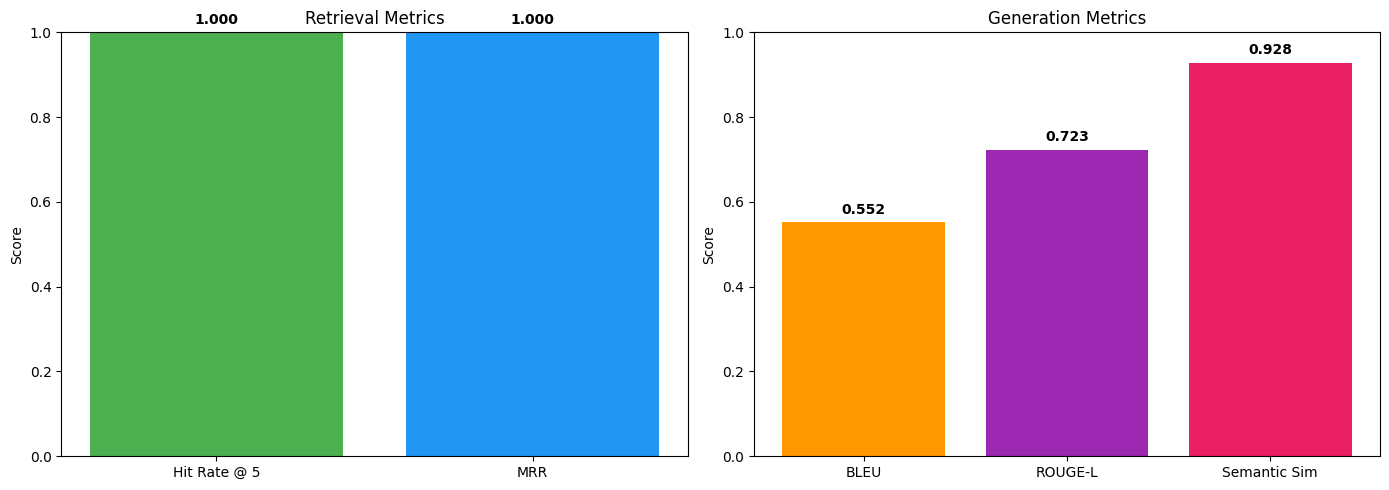

In [28]:
# Optional: Visualize results
try:
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Retrieval metrics
    ax1 = axes[0]
    retrieval_metrics = ['Hit Rate @ 5', 'MRR']
    retrieval_values = [eval_df['hit_rate'].mean(), eval_df['mrr'].mean()]
    bars1 = ax1.bar(retrieval_metrics, retrieval_values, color=['#4CAF50', '#2196F3'])
    ax1.set_ylabel('Score')
    ax1.set_title('Retrieval Metrics')
    ax1.set_ylim(0, 1)
    for bar, val in zip(bars1, retrieval_values):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f'{val:.3f}', ha='center', fontweight='bold')

    # Generation metrics
    ax2 = axes[1]
    gen_metrics = ['BLEU', 'ROUGE-L', 'Semantic Sim']
    gen_values = [eval_df['bleu'].mean(), eval_df['rouge_l'].mean(), eval_df['semantic_similarity'].mean()]
    bars2 = ax2.bar(gen_metrics, gen_values, color=['#FF9800', '#9C27B0', '#E91E63'])
    ax2.set_ylabel('Score')
    ax2.set_title('Generation Metrics')
    ax2.set_ylim(0, 1)
    for bar, val in zip(bars2, gen_values):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f'{val:.3f}', ha='center', fontweight='bold')

    plt.tight_layout()

    # Save figure
    fig_path = output_dir / "evaluation_metrics.png"
    plt.savefig(fig_path, dpi=150, bbox_inches='tight')
    print(f"💾 Saved visualization to: {fig_path}")

    plt.show()

except ImportError:
    print("⚠️ matplotlib not available. Install with: pip install matplotlib")